> **Portfolio-cleanup copy of the original university notebook** (Deakin University, author: Kudzai Shava).
> Modelling code, parameters and saved outputs are unchanged. Only these edits were made: Dropbox download cells and links removed, data paths made relative (`../data/T1.csv`), and this note added.
>
> **Read before relying on any result here:**
> - **Target leakage in the regression section.** `LV ActivePower (kW)` is the target *and* is included in the feature list, so the near-zero errors (MSE ~1e-31 for Linear Regression) are not meaningful. See `wind_scada_revised.ipynb` for a corrected version.
> - **The "IDK" section is not the published Isolation Distributional Kernel.** It uses the standard deviation of per-tree Random Forest predictions as an uncertainty flag.
> - The Isolation Forest results are unsupervised: no failure or anomaly labels exist, and `contamination=0.01` fixes roughly 1% of rows as anomalies by construction.
> - The split is random (not time-ordered) and the scaler is fitted before the split.
> - Saved outputs were produced in Google Colab; see `docs/technical-review.md` for what was re-run.
> - The pasted markdown cell about an "internship project" is chat text left in the original; it is not part of the analysis.


In [ ]:
# Original cell downloaded the data from private Dropbox copies with !wget (links removed).
# See ../data/README.md for the dataset sources and download instructions.
# Place the CSV files in ../data/ before running the cells below.

# EDA

In [ ]:
import pandas as pd

df = pd.read_csv('../data/T1.csv')
df

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
0,01 01 2018 00:00,380.047791,5.311336,416.328908,259.994904
1,01 01 2018 00:10,453.769196,5.672167,519.917511,268.641113
2,01 01 2018 00:20,306.376587,5.216037,390.900016,272.564789
3,01 01 2018 00:30,419.645905,5.659674,516.127569,271.258087
4,01 01 2018 00:40,380.650696,5.577941,491.702972,265.674286
...,...,...,...,...,...
50525,31 12 2018 23:10,2963.980957,11.404030,3397.190793,80.502724
50526,31 12 2018 23:20,1684.353027,7.332648,1173.055771,84.062599
50527,31 12 2018 23:30,2201.106934,8.435358,1788.284755,84.742500
50528,31 12 2018 23:40,2515.694092,9.421366,2418.382503,84.297913


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Convert 'Date/Time' to datetime with explicit format
df['Date/Time'] = pd.to_datetime(df['Date/Time'], format='%d %m %Y %H:%M')

# Creating additional time features for deeper analysis
df['Year'] = df['Date/Time'].dt.year
df['Month'] = df['Date/Time'].dt.month
df['Day'] = df['Date/Time'].dt.day
df['Hour'] = df['Date/Time'].dt.hour

In [ ]:
df

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°),Year,Month,Day,Hour
0,2018-01-01 00:00:00,380.047791,5.311336,416.328908,259.994904,2018,1,1,0
1,2018-01-01 00:10:00,453.769196,5.672167,519.917511,268.641113,2018,1,1,0
2,2018-01-01 00:20:00,306.376587,5.216037,390.900016,272.564789,2018,1,1,0
3,2018-01-01 00:30:00,419.645905,5.659674,516.127569,271.258087,2018,1,1,0
4,2018-01-01 00:40:00,380.650696,5.577941,491.702972,265.674286,2018,1,1,0
...,...,...,...,...,...,...,...,...,...
50525,2018-12-31 23:10:00,2963.980957,11.404030,3397.190793,80.502724,2018,12,31,23
50526,2018-12-31 23:20:00,1684.353027,7.332648,1173.055771,84.062599,2018,12,31,23
50527,2018-12-31 23:30:00,2201.106934,8.435358,1788.284755,84.742500,2018,12,31,23
50528,2018-12-31 23:40:00,2515.694092,9.421366,2418.382503,84.297913,2018,12,31,23


In [ ]:
# Statistical Summary of Numerical Features
print("Statistical Summary:")
print(df.describe())

Statistical Summary:
                           Date/Time  LV ActivePower (kW)  Wind Speed (m/s)  \
count                          50530         50530.000000      50530.000000   
mean   2018-07-01 20:01:30.065307648          1307.684332          7.557952   
min              2018-01-01 00:00:00            -2.471405          0.000000   
25%              2018-04-03 05:22:30            50.677890          4.201395   
50%              2018-06-30 16:15:00           825.838074          7.104594   
75%              2018-09-26 18:57:30          2482.507568         10.300020   
max              2018-12-31 23:50:00          3618.732910         25.206011   
std                              NaN          1312.459242          4.227166   

       Theoretical_Power_Curve (KWh)  Wind Direction (°)     Year  \
count                   50530.000000        50530.000000  50530.0   
mean                     1492.175463          123.687559   2018.0   
min                         0.000000            0.000000   2

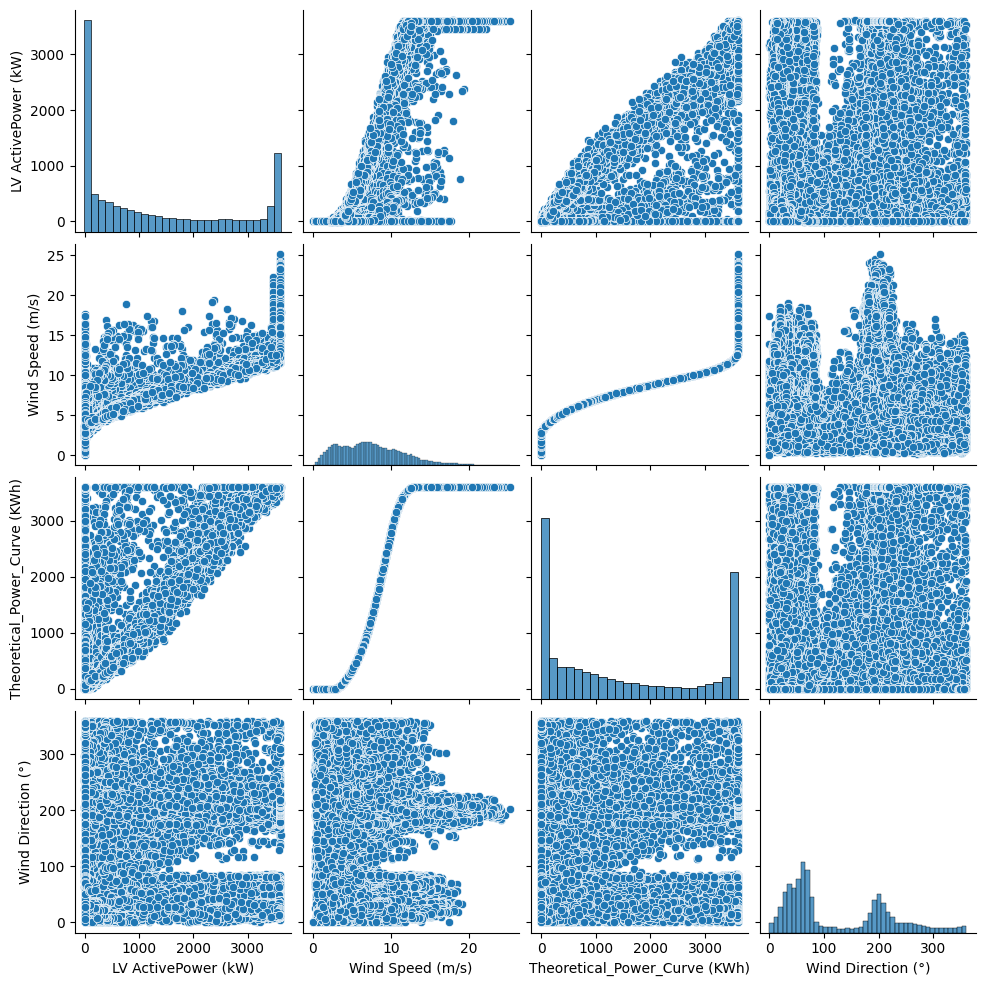

In [ ]:
# Pair Plot to visualize the relationship between features
sns.pairplot(df[['LV ActivePower (kW)', 'Wind Speed (m/s)', 'Theoretical_Power_Curve (KWh)', 'Wind Direction (°)']])
plt.show()

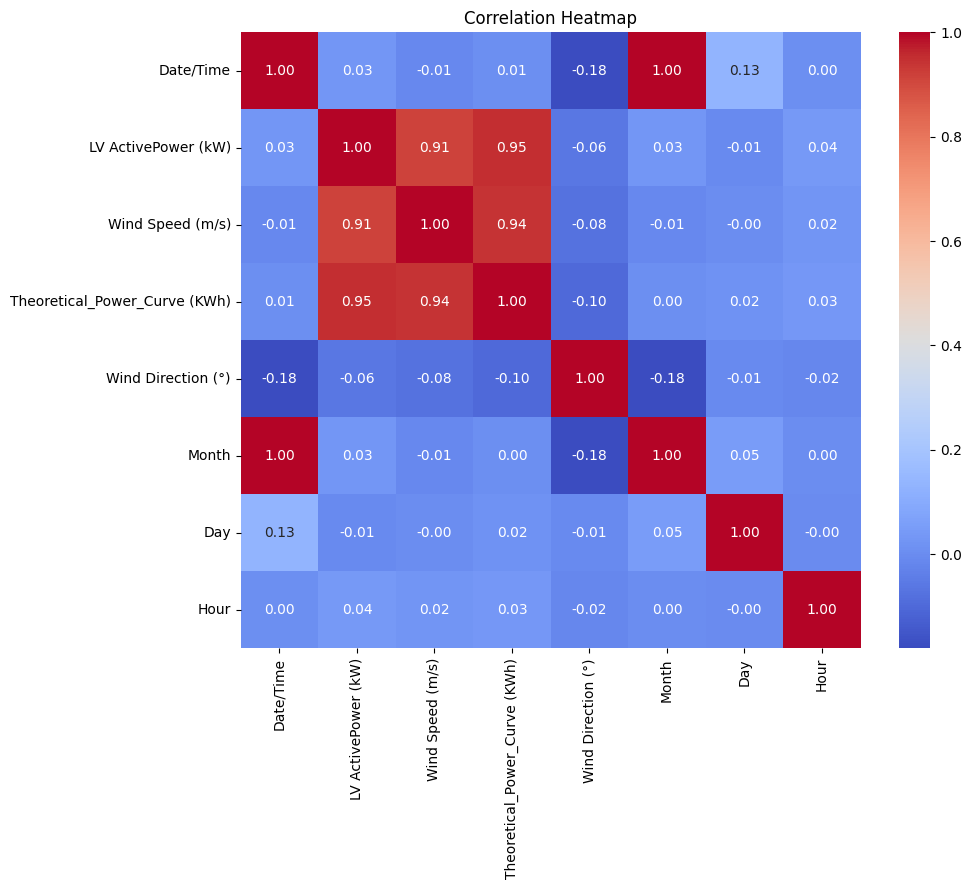

In [ ]:
# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.drop('Year',axis=1).corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

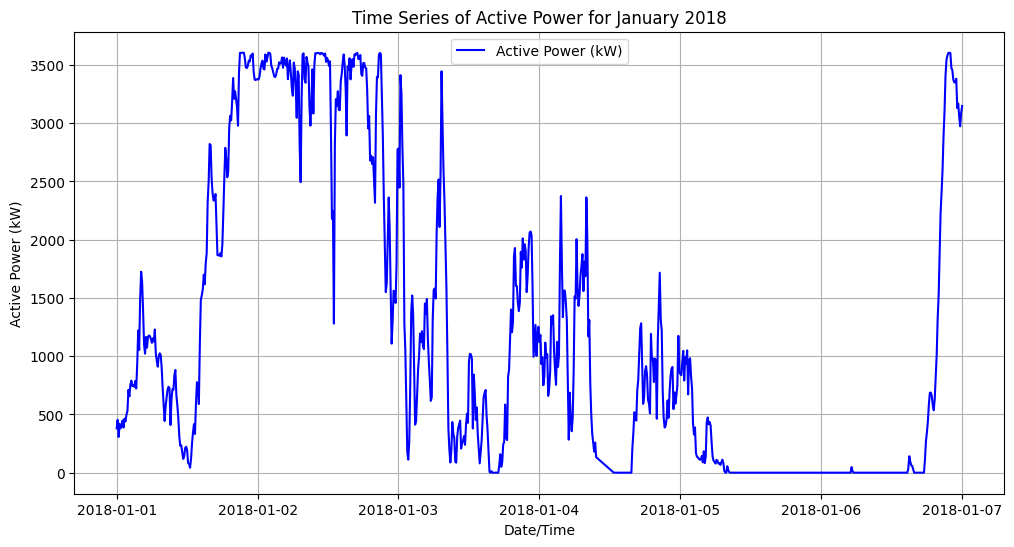

In [ ]:
# Filter the DataFrame for a specific month, e.g., January 2018
start_date = "2018-01-01"
end_date = "2018-01-7"
mask = (df['Date/Time'] >= start_date) & (df['Date/Time'] <= end_date)
filtered_df = df.loc[mask]

# Time series plot of active power for January 2018
plt.figure(figsize=(12, 6))
plt.plot(filtered_df['Date/Time'], filtered_df['LV ActivePower (kW)'], label='Active Power (kW)', color='blue')
plt.title('Time Series of Active Power for January 2018')
plt.xlabel('Date/Time')
plt.ylabel('Active Power (kW)')
plt.legend()
plt.grid(True)  # Adding grid for better readability
plt.show()

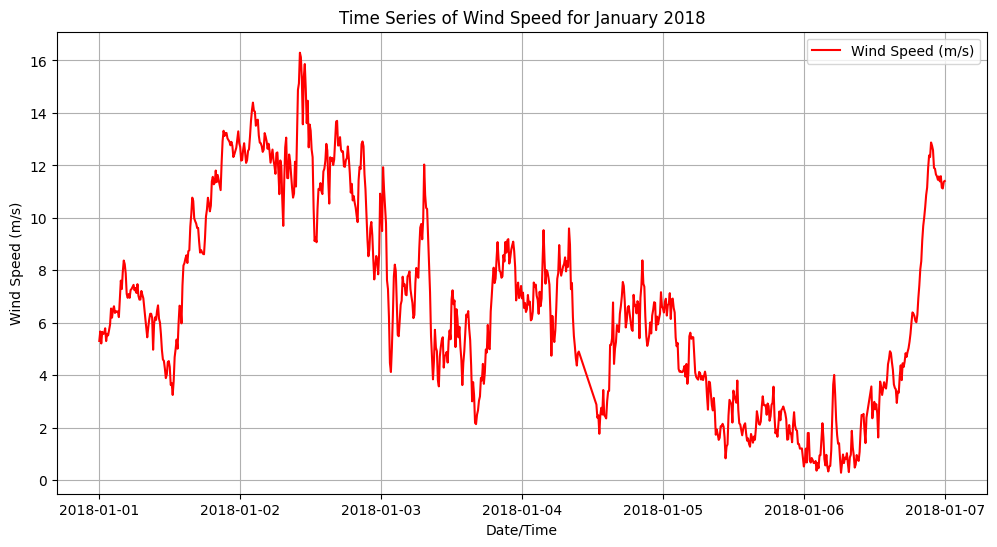

In [ ]:
# Time series plot of wind speed for January 2018
plt.figure(figsize=(12, 6))
plt.plot(filtered_df['Date/Time'], filtered_df['Wind Speed (m/s)'], label='Wind Speed (m/s)', color='red')
plt.title('Time Series of Wind Speed for January 2018')
plt.xlabel('Date/Time')
plt.ylabel('Wind Speed (m/s)')
plt.legend()
plt.grid(True)  # Adding grid for better readability
plt.show()

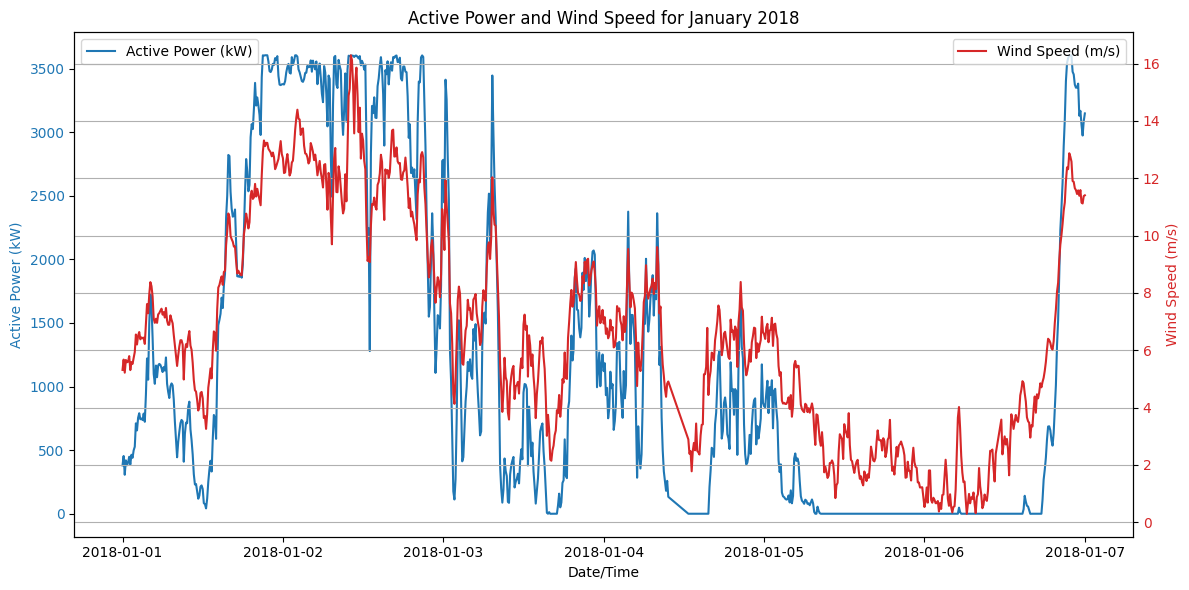

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Filter the DataFrame for a specific month, e.g., January 2018
start_date = "2018-01-01"
end_date = "2018-01-7"
mask = (df['Date/Time'] >= start_date) & (df['Date/Time'] <= end_date)
filtered_df = df.loc[mask]

# Create a plot with two y-axes
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Active Power on primary y-axis
color = 'tab:blue'
ax1.set_xlabel('Date/Time')
ax1.set_ylabel('Active Power (kW)', color=color)
ax1.plot(filtered_df['Date/Time'], filtered_df['LV ActivePower (kW)'], label='Active Power (kW)', color=color)
ax1.tick_params(axis='y', labelcolor=color)
ax1.legend(loc='upper left')

# Create a second y-axis for Wind Speed
ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis
color = 'tab:red'
ax2.set_ylabel('Wind Speed (m/s)', color=color)  # we already handled the x-label with ax1
ax2.plot(filtered_df['Date/Time'], filtered_df['Wind Speed (m/s)'], label='Wind Speed (m/s)', color=color)
ax2.tick_params(axis='y', labelcolor=color)
ax2.legend(loc='upper right')

# Title and grid
plt.title('Active Power and Wind Speed for January 2018')
fig.tight_layout()  # to make sure that the labels do not get cut off
plt.grid(True)
plt.show()


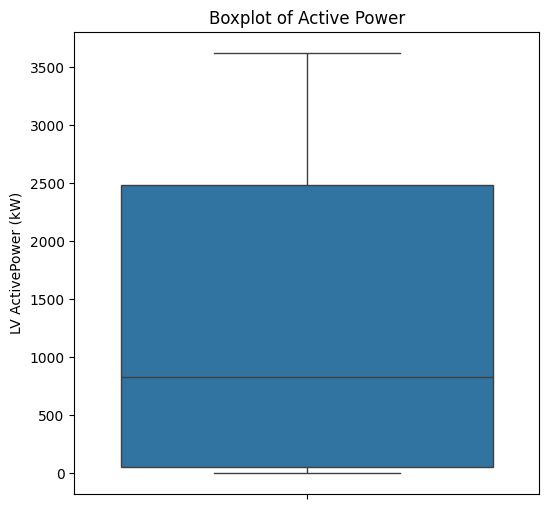

In [ ]:
# Boxplot of active power
plt.figure(figsize=(6, 6))
sns.boxplot(y=df['LV ActivePower (kW)'])
plt.title('Boxplot of Active Power')
plt.show()

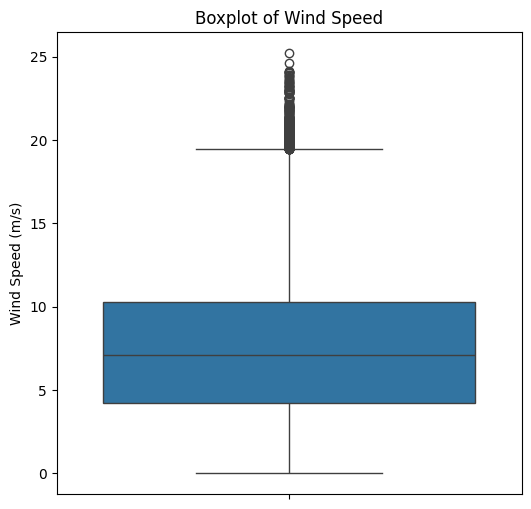

In [ ]:
# Boxplot of wind speed
plt.figure(figsize=(6, 6))
sns.boxplot(y=df['Wind Speed (m/s)'])
plt.title('Boxplot of Wind Speed')
plt.show()

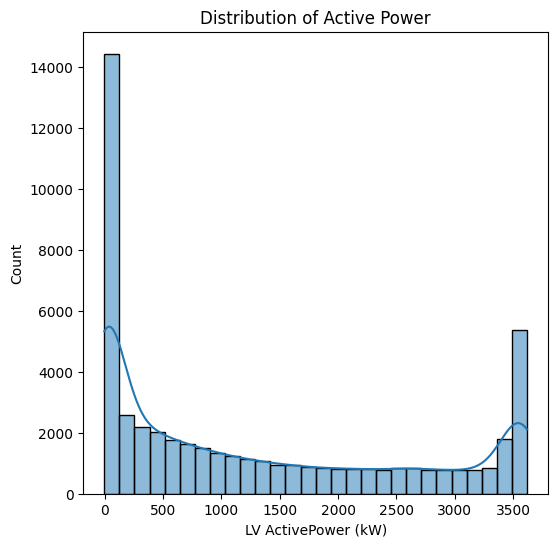

In [ ]:
# Histogram of active power
plt.figure(figsize=(6, 6))
sns.histplot(df['LV ActivePower (kW)'], kde=True)
plt.title('Distribution of Active Power')
plt.show()

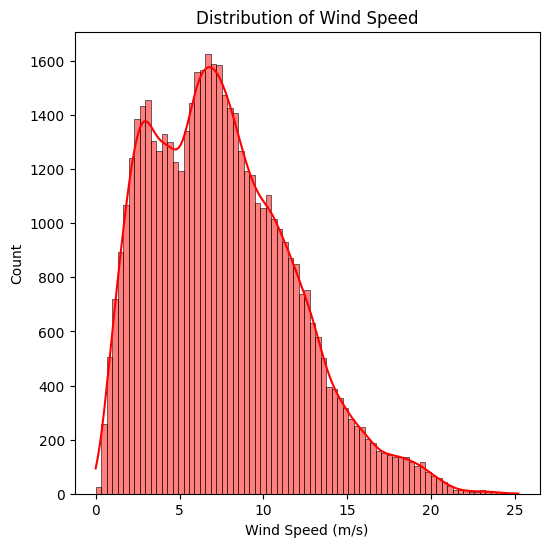

In [ ]:
# Histogram of wind speed
plt.figure(figsize=(6, 6))
sns.histplot(df['Wind Speed (m/s)'], kde=True, color='red')
plt.title('Distribution of Wind Speed')
plt.show()

# Preprocessing

In [ ]:
# Check for missing values
print(df.isnull().sum())

Date/Time                        0
LV ActivePower (kW)              0
Wind Speed (m/s)                 0
Theoretical_Power_Curve (KWh)    0
Wind Direction (°)               0
Year                             0
Month                            0
Day                              0
Hour                             0
dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Select features to scale
features_to_scale = ['LV ActivePower (kW)', 'Wind Speed (m/s)', 'Theoretical_Power_Curve (KWh)', 'Wind Direction (°)']
df_scaled = df.copy()

# Scale selected features
df_scaled[features_to_scale] = scaler.fit_transform(df[features_to_scale])


In [ ]:
from sklearn.model_selection import train_test_split

# Define the target variable and features
X = df_scaled[features_to_scale]  # or df_cleaned[features_to_scale] if using the cleaned dataset
y = df_scaled['LV ActivePower (kW)']  # assuming you want to predict Active Power

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # 20% for testing

print("Training set size:", X_train.shape[0])
print("Testing set size:", X_test.shape[0])

Training set size: 40424
Testing set size: 10106


he "LV ActivePower (kW)" metric from your dataset is indeed very relevant to the tasks described in your internship project:

Predictive Maintenance for Wind Turbines
Analyzing the "LV ActivePower (kW)" can help develop algorithms to predict potential failures in wind turbines:

Detecting Anomalies: Changes or irregular patterns in the active power output might indicate mechanical or electrical issues in the turbine. For example, a sudden drop in power output not correlated with wind speed changes could signal a malfunction.
Trend Analysis: Monitoring trends in the active power output over time can help predict wear and tear or impending failures before they lead to outages.
Consumption Monitoring
While "LV ActivePower (kW)" directly measures output rather than consumption, it is indirectly related to consumption monitoring:

Grid Stability: Active power output data is essential for assessing the stability of the power grid. It helps in understanding how much renewable energy is being fed into the grid, which is crucial for balancing supply and demand.
Energy Production Assessment: Knowing the output of wind turbines allows for better management of energy resources, which can aid in detecting discrepancies or inefficiencies in the broader energy consumption patterns on the grid.
In summary, the active power data from wind turbines, such as the "LV ActivePower (kW)", provides valuable insights into both the operational efficiency of the turbines and the overall management of energy production. This information is essential for developing predictive maintenance strategies and for monitoring and managing energy consumption patterns on the grid, aligning well with the goals of your project.

# Modeling

# IDK

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import time

# Define the models
models = [
    ("Linear Regression", LinearRegression()),
    ("Random Forest", RandomForestRegressor(n_estimators=100, random_state=42))]

def apply_idk_logic(model, X, threshold):
    # Ensure the model is an ensemble method
    if hasattr(model, "estimators_"):
        # Predict using the model and calculate the standard deviation of the predictions
        predictions = np.array([tree.predict(X) for tree in model.estimators_])
        mean_predictions = np.mean(predictions, axis=0)
        std_predictions = np.std(predictions, axis=0)

        # Apply IDK logic
        idk_indices = std_predictions > threshold
        return mean_predictions, idk_indices
    else:
        # For non-ensemble models, return regular predictions and no IDK indices
        predictions = model.predict(X)
        return predictions, np.array([False] * len(predictions))

results_list_idk = []

# Iterate over each model, train, apply IDK logic if applicable, and evaluate
for name, model in tqdm(models):
    start_time = time.time()

    # Train the model
    model.fit(X_train, y_train)
    train_time = time.time() - start_time

    # Apply IDK logic or regular prediction
    predictions, idk_indices = apply_idk_logic(model, X_test, 0.1)  # 0.1 as an example threshold

    # Replace uncertain predictions with np.nan for IDK
    predictions[idk_indices] = np.nan

    valid_indices = ~idk_indices
    mse = mean_squared_error(y_test[valid_indices], predictions[valid_indices])
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test[valid_indices], predictions[valid_indices])
    eval_time = time.time() - train_time - start_time

    # Save results
    results_list_idk.append({
        "Model": name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "Training Time (s)": train_time,
        "Evaluation Time (s)": eval_time
    })


  0%|          | 0/2 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/sklearn/base.py:432: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/base.py:432: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/base.py:432: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/base.py:432: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/base.py:432: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/base.py:432: UserWarning: X has feature names, but DecisionT

In [ ]:
# Convert results list to DataFrame
results_df = pd.DataFrame(results_list_idk)

# Display the DataFrame
results_df


,Model,MSE,RMSE,MAE,Training Time (s),Evaluation Time (s)
0,Linear Regression,7.747488e-31,8.801982e-16,7.703297e-16,0.013304,0.004931
1,Random Forest,5.060860e-09,7.113972e-05,4.017089e-05,16.510349,0.501536


# iNNE

In [ ]:
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# Load the data
data_path = '../data/T1.csv'
data = pd.read_csv(data_path)

# Preprocessing
data['Date/Time'] = pd.to_datetime(data['Date/Time'], format='%d %m %Y %H:%M')  # Specify the correct format
data.fillna(data.mean(), inplace=True)  # Handling missing values by replacing them with the mean

# Feature scaling
scaler = StandardScaler()
scaled_features = scaler.fit_transform(data[['LV ActivePower (kW)', 'Wind Speed (m/s)', 'Theoretical_Power_Curve (KWh)', 'Wind Direction (°)']])

# Isolation Forest for anomaly detection
iso_forest = IsolationForest(n_estimators=100, contamination=0.01)  # contamination is the expected proportion of outliers
iso_forest.fit(scaled_features)

# Predictions
data['anomaly_score'] = iso_forest.decision_function(scaled_features)
data['is_anomaly'] = iso_forest.predict(scaled_features)

# Identifying potential faults
faults = data[data['is_anomaly'] == -1]  # -1 indicates an outlier/anomaly

faults[['Date/Time', 'LV ActivePower (kW)', 'Wind Speed (m/s)', 'Theoretical_Power_Curve (KWh)', 'Wind Direction (°)', 'anomaly_score']]

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°),anomaly_score
1474,2018-01-11 09:10:00,558.426514,10.879940,3228.384864,166.755905,-0.000106
1475,2018-01-11 09:20:00,0.000000,10.971560,3262.307881,167.217804,-0.022320
1476,2018-01-11 09:30:00,0.000000,10.526490,3078.324921,0.000000,-0.012797
1477,2018-01-11 09:40:00,0.000000,10.432140,3032.812040,179.270004,-0.017422
1838,2018-01-13 22:00:00,980.982117,14.878930,3600.000000,42.458939,-0.006347
...,...,...,...,...,...,...
49533,2018-12-25 01:50:00,2381.025879,9.217463,2285.016857,351.979797,-0.002129
49621,2018-12-25 16:30:00,826.080627,12.151810,3543.608216,38.043621,-0.006143
49690,2018-12-26 04:00:00,186.179794,10.206590,2914.007032,14.107920,-0.013778
50222,2018-12-29 20:40:00,262.151611,10.266920,2947.205252,5.318913,-0.009773


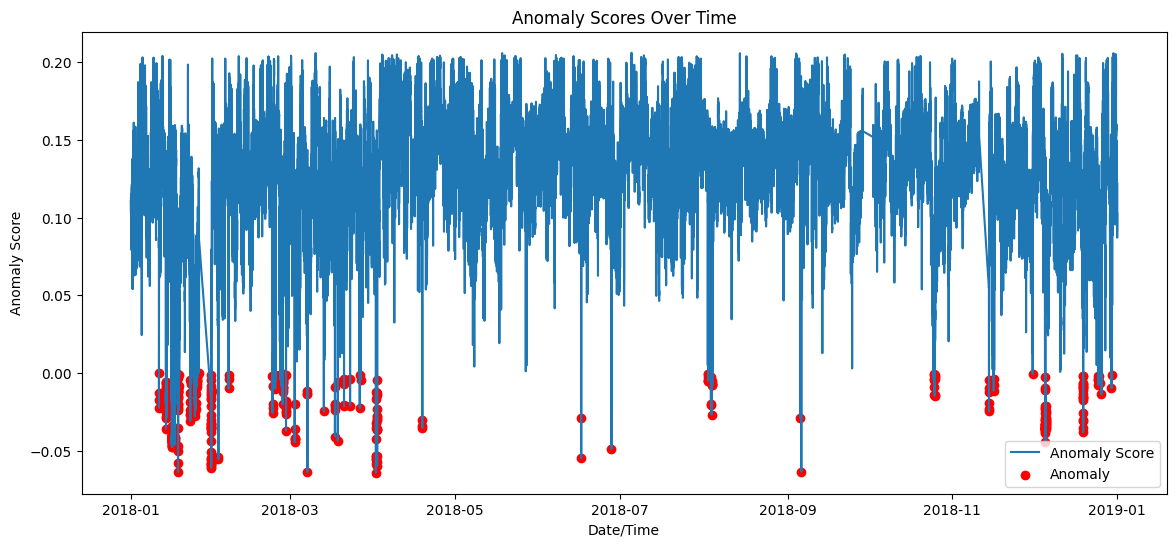

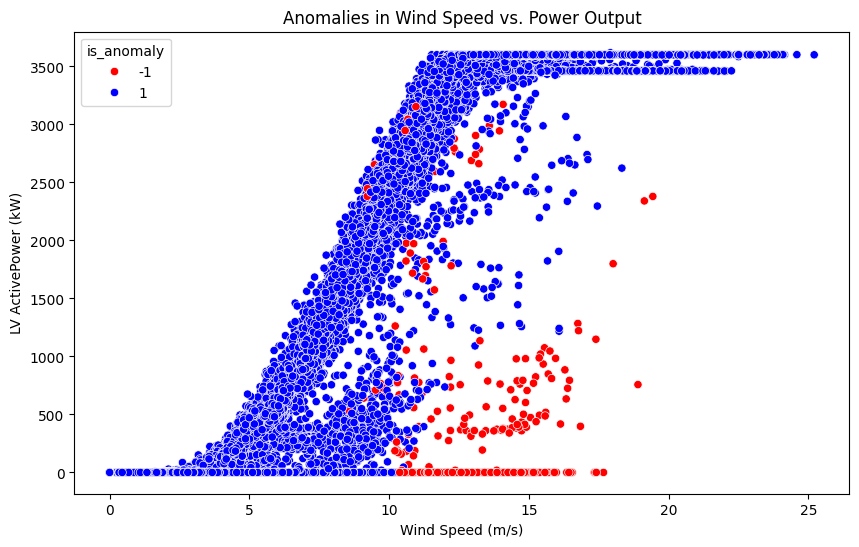

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure that your Date/Time column is set as the index if it isn't already
data.set_index('Date/Time', inplace=True)

# Plotting anomaly scores over time
plt.figure(figsize=(14, 6))
plt.plot(data.index, data['anomaly_score'], label='Anomaly Score')
plt.scatter(data.index[data['is_anomaly'] == -1], data['anomaly_score'][data['is_anomaly'] == -1], color='r', label='Anomaly')
plt.xlabel('Date/Time')
plt.ylabel('Anomaly Score')
plt.title('Anomaly Scores Over Time')
plt.legend()
plt.show()

# Scatter plot of Anomalies using Wind Speed and Power Output
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Wind Speed (m/s)', y='LV ActivePower (kW)', hue='is_anomaly', data=data, palette={1: 'blue', -1: 'red'})
plt.xlabel('Wind Speed (m/s)')
plt.ylabel('LV ActivePower (kW)')
plt.title('Anomalies in Wind Speed vs. Power Output')
plt.show()
